# Student outcome classifiers: training notebook

Machine Learning, Assignment 2 (M.Tech AIML).

This notebook runs the same steps as `train_models.py`, one cell at a time, so the output of every step is visible. The sections follow the assignment PDF:

- **Step 1, dataset choice:** UCI dataset 697, with at least 12 features and 500 rows
- **Step 2, models and metrics:** the five classifiers, each scored with Accuracy, AUC, Precision, Recall, F1 and MCC
- **Step 3, repository:** the trained models saved in `model/`, the test rows in `test_data.csv`, and the preprocessing stored inside each saved model

On a new machine (for example the BITS Virtual Lab), install the packages first with `pip install -r requirements.txt`.

In [1]:
# On a fresh machine, uncomment the next line once to install the packages
# %pip install -r requirements.txt

import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold

import train_models as tm
from charts import confusion_figure, dot_plot
from prep import RAW_FEATURES, TARGET, build_preprocessor, read_csv_bytes, split_features_and_target
from scoring import METRICS, confusion_counts, predict_with, score_model

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

## Step 1: the dataset

*Predict Students' Dropout and Academic Success*, UCI Machine Learning Repository, id 697. One row per student. The target has three values: Dropout, Enrolled, Graduate. The raw file is separated by semicolons.

In [2]:
raw = pd.read_csv(tm.DATA_FILE, sep=";")
n_rows, n_features = raw.shape[0], raw.shape[1] - 1   # last column is the target
print(f"rows: {n_rows}   features: {n_features}")
print("missing cells:", int(raw.isna().sum().sum()), "  duplicate rows:", int(raw.duplicated().sum()))

# the PDF asks for at least 12 features and 500 instances
assert n_rows >= 500 and n_features >= 12
raw.head(3)

rows: 4424   features: 36
missing cells: 0   duplicate rows: 0


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.0,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.0,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.0,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout


Two headers in the raw file are awkward: one ends in a tab and `Nacionality` is misspelt. `tidy_columns()` in `prep.py` turns every header into snake_case and fixes the spelling. The app runs the same function on uploaded files.

In [3]:
print([name for name in raw.columns if name != name.strip() or name == "Nacionality"])

table = tm.load_table()   # tidy names, then check all 36 features and the target are there
print(table.columns[:8].tolist())

['Daytime/evening attendance\t', 'Nacionality']
['marital_status', 'application_mode', 'application_order', 'course', 'daytime_evening_attendance', 'previous_qualification', 'previous_qualification_grade', 'nationality']


### Outcome mix

The classes are not balanced, so precision, recall and F1 are reported as macro averages later on: each outcome counts the same, however many students it has.

target
Graduate    0.499
Dropout     0.321
Enrolled    0.179


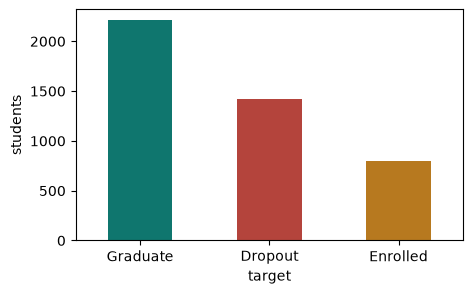

In [4]:
counts = table[TARGET].value_counts()
print((counts / len(table)).round(3).to_string())

ax = counts.plot.bar(color=["#0f766e", "#b4443c", "#b7791f"], rot=0, figsize=(5, 3))
ax.set_ylabel("students")
plt.show()

### A first look at what separates the outcomes

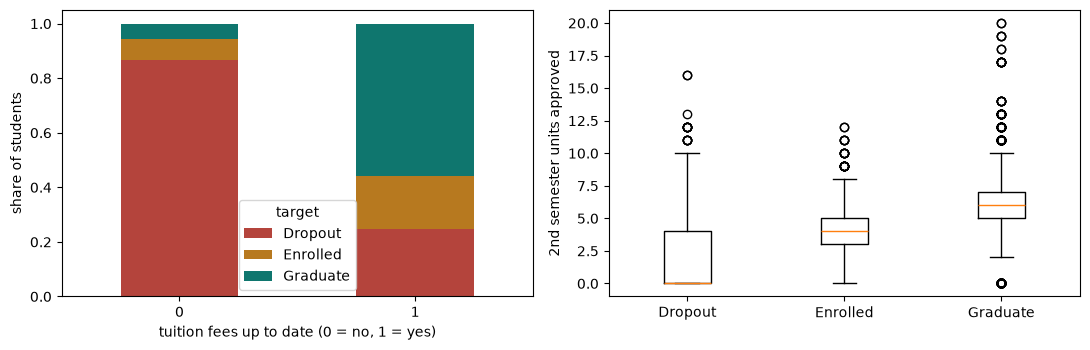

target,Dropout,Enrolled,Graduate
tuition_fees_up_to_date,,,
0,0.866,0.080,0.055
1,0.247,0.193,0.560


In [5]:
outcome_order = ["Dropout", "Enrolled", "Graduate"]
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))

# outcome mix for students with and without their fees paid up
fees = pd.crosstab(table["tuition_fees_up_to_date"], table[TARGET], normalize="index")[outcome_order]
fees.plot.bar(stacked=True, ax=left, rot=0, color=["#b4443c", "#b7791f", "#0f766e"])
left.set_xlabel("tuition fees up to date (0 = no, 1 = yes)")
left.set_ylabel("share of students")

# units passed in the 2nd semester, per outcome
right.boxplot([table.loc[table[TARGET] == o, "curricular_units_2nd_sem_approved"] for o in outcome_order])
right.set_xticks([1, 2, 3], outcome_order)
right.set_ylabel("2nd semester units approved")

fig.tight_layout()
plt.show()
fees.round(3)

### Columns that move together

Gaussian Naive Bayes assumes the inputs are independent once the outcome is known. The semester columns clearly are not:

In [6]:
semester_cols = [c for c in RAW_FEATURES if c.startswith("curricular_units")]
corr = table[semester_cols].corr()
strong = [
    (a, b, round(corr.loc[a, b], 2))
    for i, a in enumerate(semester_cols)
    for b in semester_cols[i + 1:]
    if abs(corr.loc[a, b]) > 0.8
]
pd.DataFrame(strong, columns=["column A", "column B", "r"])

,column A,column B,r
0,curricular_units_1st_sem_credited,curricular_units_2nd_sem_credited,0.94
1,curricular_units_1st_sem_enrolled,curricular_units_2nd_sem_enrolled,0.94
2,curricular_units_1st_sem_approved,curricular_units_2nd_sem_approved,0.90
3,curricular_units_1st_sem_grade,curricular_units_2nd_sem_grade,0.84


## Train / test split

80/20, stratified on the outcome so both parts keep the same mix (`random_state=5278`). The 20% part is saved as `test_data.csv` at the end. It is used once per model, after tuning, and never for training.

In [7]:
train, test = tm.split_table(table)
x_train, x_test = tm.model_inputs(train), tm.model_inputs(test)
y_train, y_test = train[TARGET], test[TARGET]
labels = sorted(y_train.unique())

pd.DataFrame({"train rows": y_train.value_counts(), "test rows": y_test.value_counts()})

,train rows,test rows
target,,
Graduate,1767,442
Dropout,1137,284
Enrolled,635,159


## Preprocessing

Written once in `prep.py` and stored inside every saved model, so the Streamlit app applies exactly the same steps:

- integer codes (course, application mode, parents' jobs and qualifications, ...) are one-hot encoded; codes seen in under 1% of the training rows share one bucket
- grades, unit counts and rates are standardised
- yes/no columns are passed through as 0/1
- three columns are added: the share of enrolled units passed in each semester, and the change in average grade between the semesters

In [8]:
cols = ["curricular_units_2nd_sem_enrolled", "curricular_units_2nd_sem_approved", "pass_rate_2nd_sem", "grade_change"]
display(x_train[cols].head())

prep_step = build_preprocessor(tm.USE_EXTRA).fit(x_train)
print("columns going into the models after encoding:", len(prep_step.get_feature_names_out()))

,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_approved,pass_rate_2nd_sem,grade_change
423,8,8,1.0,0.000000
86,5,5,1.0,1.100000
3945,6,6,1.0,0.428571
3614,6,6,1.0,-1.309524
1231,6,6,1.0,-0.500000


columns going into the models after encoding: 111


### Do the added columns help?

Quick check with two baselines: 5-fold macro-F1 on the training rows only.

In [9]:
folds = StratifiedKFold(n_splits=tm.FOLDS, shuffle=True, random_state=tm.SEED)
feature_check = tm.check_extra_features(x_train, y_train, folds)
pd.DataFrame(feature_check).T

,raw_columns_only,with_extra_columns
Logistic Regression,0.7099,0.7105
"SVM (rbf, defaults)",0.7030,0.7077


The gain is small (under 0.005) but not negative, so the columns are kept (`USE_EXTRA = True` in `train_models.py`).

## Step 2: the five models

Each model goes through the same function, `tune_and_score()` in `train_models.py`:

1. grid search with 5-fold stratified cross-validation on the training rows, scored by macro-F1
2. the best setting is refitted on all training rows
3. one score on the test rows with the six metrics from the PDF: Accuracy, AUC, Precision, Recall, F1, MCC

Precision, recall and F1 are macro averages. AUC is the macro one-vs-rest AUC.

In [10]:
fitted = {}   # model name -> fitted pipeline, chosen settings and scores

def run(name):
    fitted[name] = tm.tune_and_score(name, x_train, y_train, x_test, y_test, labels, folds)
    record = fitted[name]["record"]
    print("searched", record["grid_size"], "settings; best:", record["best_params"])
    print("5-fold CV macro-F1:", record["cv_macro_f1"])
    display(pd.DataFrame([record["holdout"]], index=[name]))
    confusion_figure(confusion_counts(y_test, fitted[name]["predicted"], labels), as_share=False)
    plt.show()

### 1. Logistic Regression

Tuned: `C` (how strongly the weights are held back) and whether the classes get balanced weights.

searched 10 settings; best: {'C': 0.1, 'class_weight': 'balanced'}
5-fold CV macro-F1: 0.7137


,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.7548,0.8814,0.7117,0.7113,0.7095,0.6054


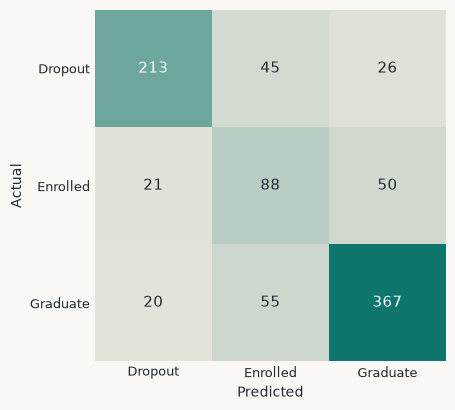

In [11]:
run("Logistic Regression")

### 2. Decision Tree

Tuned: depth, smallest leaf size, split criterion and class weights. A shallow tree is easier to read and less likely to memorise the training rows.

searched 96 settings; best: {'class_weight': None, 'criterion': 'gini', 'max_depth': 4, 'min_samples_leaf': 10}
5-fold CV macro-F1: 0.6919


,Accuracy,AUC,Precision,Recall,F1,MCC
Decision Tree,0.7243,0.841,0.6791,0.6561,0.6632,0.5492


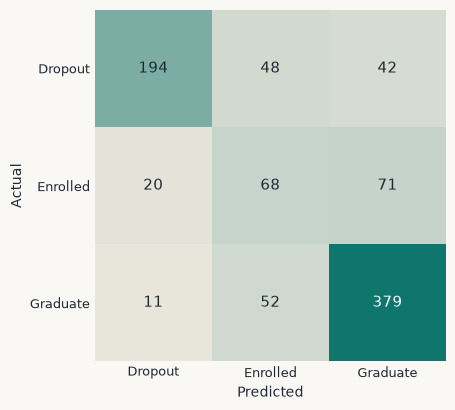

In [12]:
run("Decision Tree")

### 3. K-Nearest Neighbours

Tuned: number of neighbours, uniform or distance weighting, and Manhattan or Euclidean distance.

searched 20 settings; best: {'n_neighbors': 15, 'p': 1, 'weights': 'uniform'}
5-fold CV macro-F1: 0.6419


,Accuracy,AUC,Precision,Recall,F1,MCC
KNN,0.7412,0.8519,0.7123,0.6285,0.6418,0.573


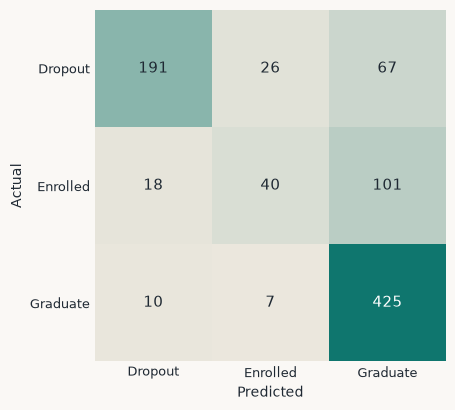

In [13]:
run("KNN")

### 4. Naive Bayes (Gaussian)

Gaussian rather than Multinomial, because inflation and GDP can be negative and Multinomial NB only accepts non-negative counts. Tuned: `var_smoothing`.

searched 9 settings; best: {'var_smoothing': 0.1}
5-fold CV macro-F1: 0.6414


,Accuracy,AUC,Precision,Recall,F1,MCC
Naive Bayes,0.7028,0.8126,0.6561,0.6211,0.6295,0.5099


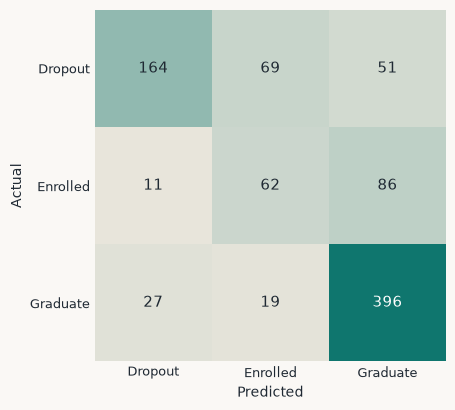

In [14]:
run("Naive Bayes")

### 5. Support Vector Machine

RBF kernel. Tuned: `C`, `gamma` and class weights. Afterwards the best SVM is wrapped in a sigmoid calibrator so it can give probabilities, which AUC needs.

searched 50 settings; best: {'C': 100.0, 'class_weight': 'balanced', 'gamma': 0.001}
5-fold CV macro-F1: 0.7188


,Accuracy,AUC,Precision,Recall,F1,MCC
Support Vector Machine,0.7831,0.8582,0.7403,0.7201,0.7283,0.6428


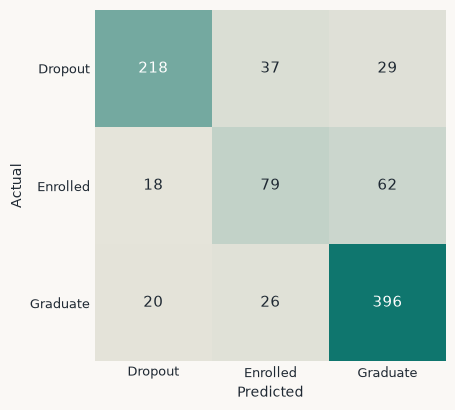

In [15]:
run("Support Vector Machine")

## Comparison of the five models

These are the numbers in the README comparison table (PDF Step 5).

In [16]:
comparison = pd.DataFrame(
    [{"ML Model Name": name, **item["metrics"]} for name, item in fitted.items()]
).set_index("ML Model Name")[METRICS].round(4)
comparison

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.7548,0.8814,0.7117,0.7113,0.7095,0.6054
Decision Tree,0.7243,0.8410,0.6791,0.6561,0.6632,0.5492
KNN,0.7412,0.8519,0.7123,0.6285,0.6418,0.5730
Naive Bayes,0.7028,0.8126,0.6561,0.6211,0.6295,0.5099
Support Vector Machine,0.7831,0.8582,0.7403,0.7201,0.7283,0.6428


In [17]:
# F1 for each outcome: Enrolled is the hard one for every model
pd.DataFrame({name: item["record"]["holdout_f1_by_class"] for name, item in fitted.items()}).T.round(4)

,Dropout,Enrolled,Graduate
Logistic Regression,0.7918,0.5072,0.8294
Decision Tree,0.7623,0.4159,0.8116
KNN,0.7594,0.3448,0.8213
Naive Bayes,0.6749,0.4013,0.8123
Support Vector Machine,0.8074,0.5249,0.8525


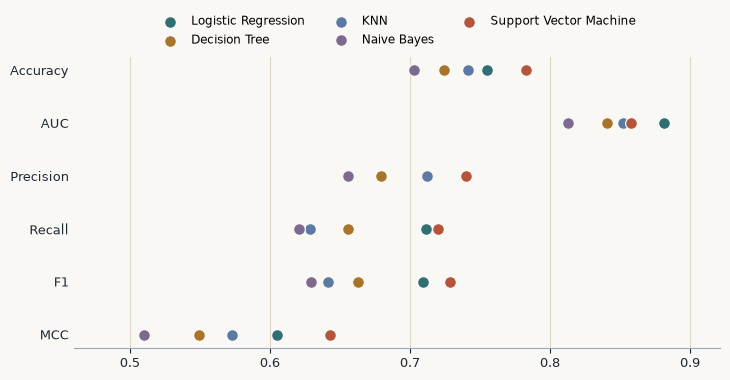

In [18]:
dot_plot(comparison)
plt.show()

## Step 3: save the models and the test file

Writes `model/*.joblib` (one pipeline per model: preprocessing + classifier), `model/holdout_metrics.csv`, `model/training_summary.json` (settings, scores and the column list the app needs) and `test_data.csv`.

In [19]:
tm.write_outputs(table, train, test, labels, feature_check, fitted)
sorted(p.name for p in tm.MODEL_DIR.iterdir())

['decision_tree.joblib',
 'holdout_metrics.csv',
 'knn.joblib',
 'logistic_regression.joblib',
 'naive_bayes.joblib',
 'svm.joblib',
 'training_summary.json']

## Check: score the saved files the way the app does

The PDF says the app must load the saved models and must not retrain them. This cell does what the app does: read `test_data.csv`, load each `.joblib` file and only call predict.

In [20]:
summary = json.loads((tm.MODEL_DIR / "training_summary.json").read_text(encoding="utf-8"))
x_check, y_check = split_features_and_target(
    read_csv_bytes((tm.HERE / "test_data.csv").read_bytes()),
    summary["feature_columns"],
    summary["labels"],
)

rows = {}
for name, info in summary["models"].items():
    saved = joblib.load(tm.MODEL_DIR / info["file"])
    predicted, proba = predict_with(saved, x_check, summary["labels"])
    rows[name] = score_model(y_check, predicted, proba, summary["labels"])

reloaded = pd.DataFrame(rows).T[METRICS].round(4)
print("matches the comparison table:", np.allclose(reloaded.to_numpy(), comparison.to_numpy()))
reloaded

matches the comparison table: True


,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.7548,0.8814,0.7117,0.7113,0.7095,0.6054
Decision Tree,0.7243,0.8410,0.6791,0.6561,0.6632,0.5492
KNN,0.7412,0.8519,0.7123,0.6285,0.6418,0.5730
Naive Bayes,0.7028,0.8126,0.6561,0.6211,0.6295,0.5099
Support Vector Machine,0.7831,0.8582,0.7403,0.7201,0.7283,0.6428


The Streamlit page (`app.py`) reads the same files. Start it with `streamlit run app.py`.